In [ ]:
#loading the csv file
from google.colab import files

uploaded=files.upload()
path=list(uploaded.keys())[0]

Saving data_updated.csv to data_updated.csv


In [ ]:
import pandas as pd

data=pd.read_csv(path
                 )
data.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
data["Target"].value_counts()

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


**Data Preprocessing**

In [ ]:
#importing libraries

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

Feature vector and target vector:

In [ ]:
X = data.drop("Target", axis= 1)
y= data["Target"].replace({'Graduate': 0, 'Dropout':1, 'Enrolled':2}).astype(int)

/tmp/ipykernel_227/4261324535.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y= data["Target"].replace({'Graduate': 0, 'Dropout':1, 'Enrolled':2}).astype(int)


In [ ]:
#define categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

**Splitting data and One-Hot Encoding**

In [ ]:
#do one hot encoding
from sklearn.preprocessing import OneHotEncoder

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)


In [ ]:
y_test.shape

(885,)

**Balancing**

In [ ]:
#UnderSampling
from imblearn.under_sampling import RandomUnderSampler

undersampler = RandomUnderSampler(sampling_strategy= 'auto', random_state= 42)
X_resampled_under, y_resampled_under = undersampler.fit_resample(X_train_en,y_train)

print(y_resampled_under.value_counts())
print(y_resampled_under.shape)

Target
0    635
1    635
2    635
Name: count, dtype: int64
(1905,)


In [ ]:
#SMOTE method
from imblearn.over_sampling import SMOTE

smote= SMOTE(sampling_strategy = 'auto', random_state= 42)
X_resampled_smote, y_resampled_smote = smote.fit_resample(X_train_en, y_train)
y_resampled_smote.value_counts()
y_resampled_smote.shape

(5301,)

**Scaling and Standardization**

In [ ]:
#Standardization and splitting data into training and testing

#imbalanced data
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train_en)
X_test=scaler.transform(X_test_en)

#undersampled data
scaler_under= StandardScaler()
X_train_under=scaler_under.fit_transform(X_resampled_under)

#smote data
scaler_smote= StandardScaler()
X_train_smote=scaler_smote.fit_transform(X_resampled_smote)


In [ ]:
X_test.shape

(885, 244)

In [ ]:
X_train_smote.shape

(5301, 244)

**SVM with Imbalanced Data Using linear kernel**

**For multi class classificaition using SVM -> Use OvO approach for small number of classes it is more accurate than OvA**

https://www.geeksforgeeks.org/machine-learning/multi-class-classification-using-support-vector-machines-svm/

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

**Imbalance data - RBF kernel**

In [ ]:
# Imbalance data - RBF kernel - C =1, Gamma = auto
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 'auto', # gamma = 'scale,
          C = 1.0)


rbf_svm.fit(X_train, y_train)

y_pred_imbalance1 = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = auto , C =1 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance1)))

Imbalance data - Model accuracy score with RBF kernel, gamma = auto , C =1 is : 0.7266


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 0.8347
Test set score: 0.7266


**RBF kernel, C =1, Gamma = auto - Confusion matrix**

[[404  21  17]
 [ 61 200  23]
 [ 89  31  39]]


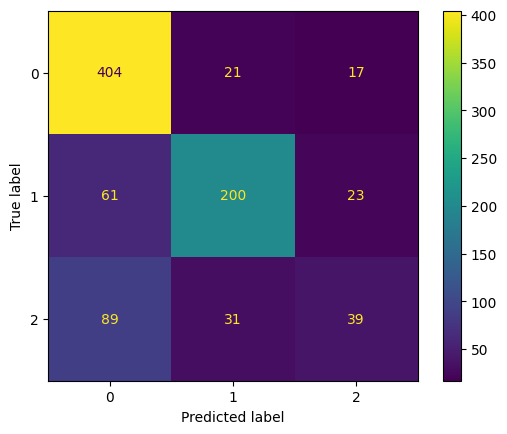

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance1)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_imbalance1))

              precision    recall  f1-score   support

           0       0.73      0.91      0.81       442
           1       0.79      0.70      0.75       284
           2       0.49      0.25      0.33       159

    accuracy                           0.73       885
   macro avg       0.67      0.62      0.63       885
weighted avg       0.71      0.73      0.70       885



In [ ]:
# Imbalance data - RBF kernel - C =100, Gamma =auto
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 'auto', # gamma = 'scale,
          C = 100.0)

rbf_svm.fit(X_train, y_train)

y_pred_imbalance = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = auto , C =100 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance)))

Imbalance data - Model accuracy score with RBF kernel, gamma = auto , C =100 is : 0.6915


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 0.9986
Test set score: 0.6915


**RBF kernel, C=100, Gamma = auto**

[[359  36  47]
 [ 37 201  46]
 [ 55  52  52]]


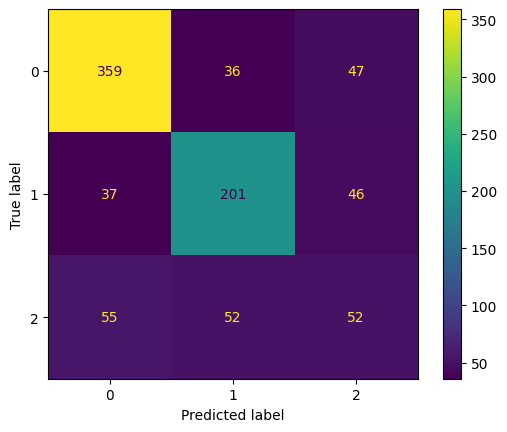

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_imbalance))

              precision    recall  f1-score   support

           0       0.80      0.81      0.80       442
           1       0.70      0.71      0.70       284
           2       0.36      0.33      0.34       159

    accuracy                           0.69       885
   macro avg       0.62      0.62      0.62       885
weighted avg       0.69      0.69      0.69       885



In [ ]:
# Imbalance data - RBF kernel - C =1, Gamma = 0.001
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 0.001, C = 1)


rbf_svm.fit(X_train, y_train)

y_pred_imbalance = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =1 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance)))

Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =1 is : 0.7322


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 0.7677
Test set score: 0.7322


**RBF Kernel, C = 1, Gamma = 0.001 - confusion matrix**

[[412  25   5]
 [ 55 208  21]
 [ 98  33  28]]


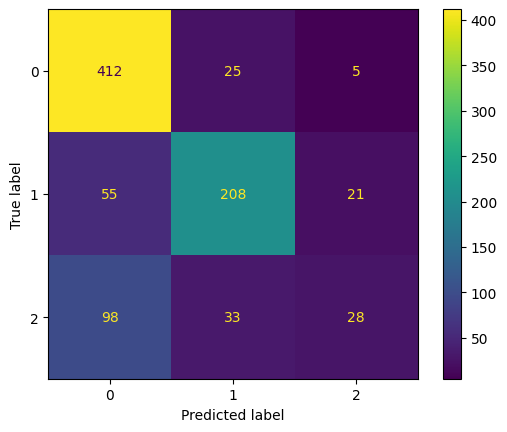

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_imbalance))

              precision    recall  f1-score   support

           0       0.73      0.93      0.82       442
           1       0.78      0.73      0.76       284
           2       0.52      0.18      0.26       159

    accuracy                           0.73       885
   macro avg       0.68      0.61      0.61       885
weighted avg       0.71      0.73      0.70       885



In [ ]:
# Imbalance data - RBF kernel - C =10, Gamma = 0.001
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 0.001, C = 10)


rbf_svm.fit(X_train, y_train)

y_pred_imbalance = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =10 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance)))

Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =10 is : 0.7571


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 0.8446
Test set score: 0.7571


**RBF kernel, C =10, Gamma = 0.001 - Confusion matrix**

[[398  20  24]
 [ 28 219  37]
 [ 66  40  53]]


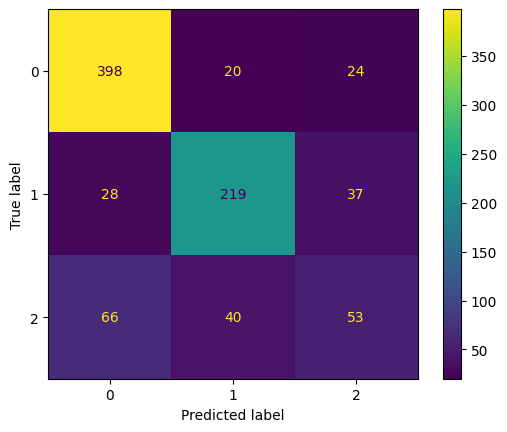

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_imbalance))

              precision    recall  f1-score   support

           0       0.81      0.90      0.85       442
           1       0.78      0.77      0.78       284
           2       0.46      0.33      0.39       159

    accuracy                           0.76       885
   macro avg       0.69      0.67      0.67       885
weighted avg       0.74      0.76      0.75       885



In [ ]:
# Imbalance data - RBF kernel - C =100, Gamma = 0.001
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 0.001, C = 100)


rbf_svm.fit(X_train, y_train)

y_pred_imbalance = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =100 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance)))

Imbalance data - Model accuracy score with RBF kernel, gamma = 0.001 , C =100 is : 0.7537


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 0.9359
Test set score: 0.7537


**RBF kernel, C =100, Gamma = 0.001 - Confusion matrix**

[[390  19  33]
 [ 28 215  41]
 [ 52  45  62]]


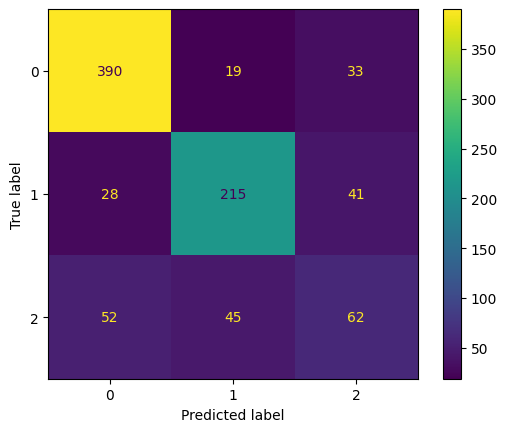

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_imbalance))

              precision    recall  f1-score   support

           0       0.83      0.88      0.86       442
           1       0.77      0.76      0.76       284
           2       0.46      0.39      0.42       159

    accuracy                           0.75       885
   macro avg       0.69      0.68      0.68       885
weighted avg       0.74      0.75      0.75       885



In [ ]:
# Imbalance data - RBF kernel - C =1, Gamma = 10
rbf_svm = SVC (kernel = 'rbf',decision_function_shape= 'ovo',
          gamma = 10, C = 1)

#higher Gamma -> infulence the neighbors
#low gamma -> large scale influence

rbf_svm.fit(X_train, y_train)

y_pred_imbalance = rbf_svm.predict(X_test)

print('Imbalance data - Model accuracy score with RBF kernel, gamma = 10 , C =1 is : {0:0.4f}'. format(accuracy_score(y_test, y_pred_imbalance)))

Imbalance data - Model accuracy score with RBF kernel, gamma = 10 , C =1 is : 0.4994


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbf_svm.score(X_train, y_train)))

print('Test set score: {:.4f}'.format(rbf_svm.score(X_test , y_test)))

Training set score: 1.0000
Test set score: 0.4994


**RBF kernel, C =1, Gamma = 100 - Confusion matrix**

[[442   0   0]
 [284   0   0]
 [159   0   0]]


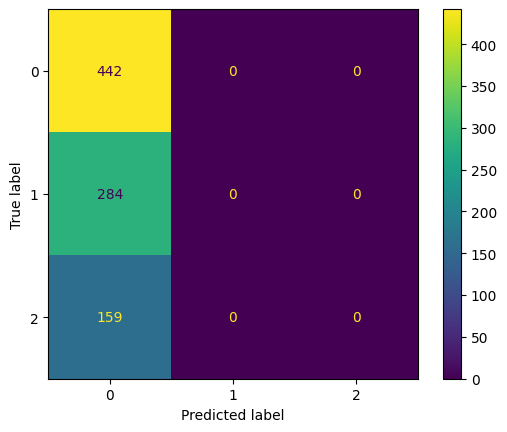

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_imbalance)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_imbalance)
plt.show()

In [ ]:
from sklearn.metrics import classification_report


print(classification_report(y_test, y_pred_imbalance, zero_division=0))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67       442
           1       0.00      0.00      0.00       284
           2       0.00      0.00      0.00       159

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885



**RBF kernel - Undersampling**

In [ ]:
# Undersampling method - RBF kernel - C =1, Gamma = auto
rbfunder_svm = SVC(kernel = 'rbf', C= 1, decision_function_shape='ovo',
                   gamma ='auto' )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 1, Gamma = auto  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 1, Gamma = auto  0.6407


In [ ]:
#Checking overfitting and underfitting:

print("Training set score : {:.4f}".format(rbfunder_svm.score(X_train_under, y_resampled_under)))

print("Testing set score {:.4f}". format(rbfunder_svm.score(X_test, y_test)))

Training set score : 0.8026
Testing set score 0.6407


**RBF kernel, C = 1, Gamma = auto - Undersampling - confusion matrix**

[[272  49 121]
 [ 11 197  76]
 [ 28  33  98]]


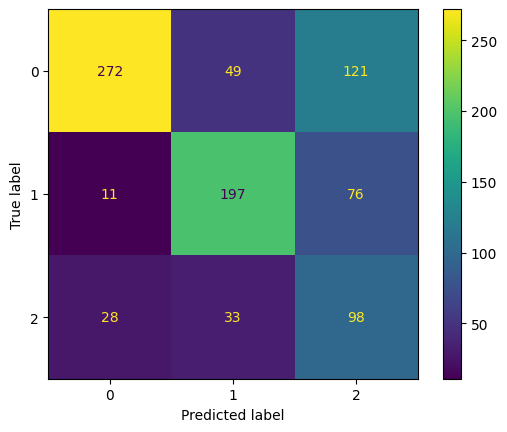

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.87      0.62      0.72       442
           1       0.71      0.69      0.70       284
           2       0.33      0.62      0.43       159

    accuracy                           0.64       885
   macro avg       0.64      0.64      0.62       885
weighted avg       0.72      0.64      0.66       885



In [ ]:
# Undersampling method - RBF kernel - C =100, Gamma = auto
rbfunder_svm = SVC(kernel = 'rbf', C= 100.0, decision_function_shape='ovo',
                   gamma ='auto' )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 100, Gamma = auto  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 100, Gamma = auto  0.6124


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score {:.4f}".format(rbfunder_svm.score(X_test, y_test)))

Training set score  1.0000
Test set score 0.6124


**RBF kernel, C = 100, Gamma = auto - Undersampling - confusion matrix**

[[267  41 134]
 [ 26 196  62]
 [ 40  40  79]]


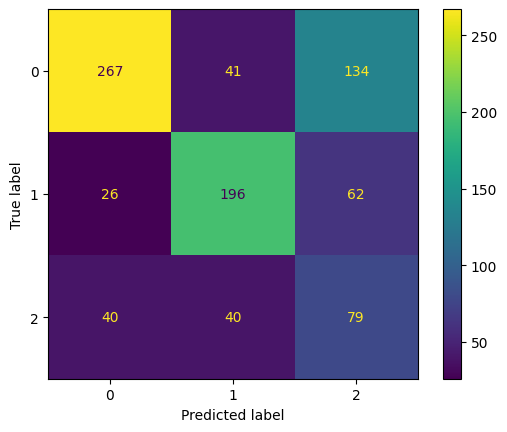

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.80      0.60      0.69       442
           1       0.71      0.69      0.70       284
           2       0.29      0.50      0.36       159

    accuracy                           0.61       885
   macro avg       0.60      0.60      0.58       885
weighted avg       0.68      0.61      0.63       885



In [ ]:
# Undersampling method - RBF kernel - C =1, Gamma = 0.001
rbfunder_svm = SVC(kernel = 'rbf', C= 1, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 1, Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 1, Gamma = 0.001  0.6384


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score {:.4f}".format(rbfunder_svm.score(X_test, y_test)))

Training set score  0.7339
Test set score 0.6384


**RBF kernel, C = 1, Gamma = 0.001 - Undersampling - confusion matrix**

[[276  35 131]
 [ 14 188  82]
 [ 34  24 101]]


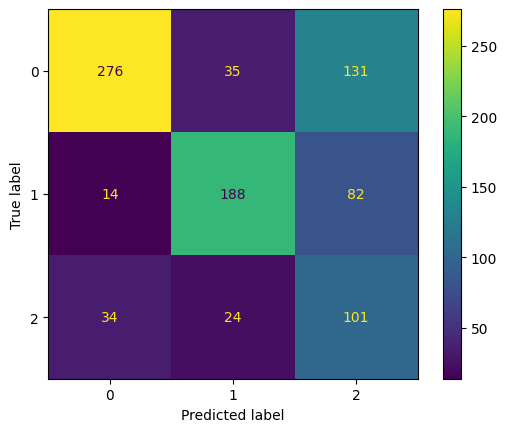

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.85      0.62      0.72       442
           1       0.76      0.66      0.71       284
           2       0.32      0.64      0.43       159

    accuracy                           0.64       885
   macro avg       0.64      0.64      0.62       885
weighted avg       0.73      0.64      0.66       885



In [ ]:
# Undersampling method - RBF kernel - C =10.0 , Gamma = 0.001
rbfunder_svm = SVC(kernel = 'rbf', C= 10.0, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 10.0 , Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 10.0 , Gamma = 0.001  0.6678


In [ ]:
y_pred_under.shape

(885,)

In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbfunder_svm.score(X_train_under, y_resampled_under)))

print('Test set score: {:.4f}'.format(rbfunder_svm.score(X_test , y_test)))

Training set score: 0.8168
Test set score: 0.6678


**RBF kernel, C = 10, Gamma = 0.001 - Undersampling - confusion matrix**

[[291  30 121]
 [ 13 205  66]
 [ 34  30  95]]


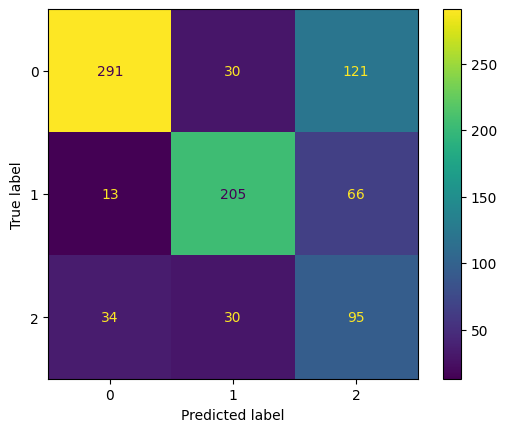

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.86      0.66      0.75       442
           1       0.77      0.72      0.75       284
           2       0.34      0.60      0.43       159

    accuracy                           0.67       885
   macro avg       0.66      0.66      0.64       885
weighted avg       0.74      0.67      0.69       885



In [ ]:
# Undersampling method - RBF kernel - C =100.0, Gamma = 0.001
rbfunder_svm = SVC(kernel = 'rbf', C= 100.0, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 100.0, Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 100.0, Gamma = 0.001  0.6610


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score {:.4f}".format(rbfunder_svm.score(X_test, y_test)))

Training set score  0.9339
Test set score 0.6610


**RBF kernel, C = 100, Gamma = 0.001 - Undersampling - confusion matrix**

[[290  29 123]
 [ 15 214  55]
 [ 35  43  81]]


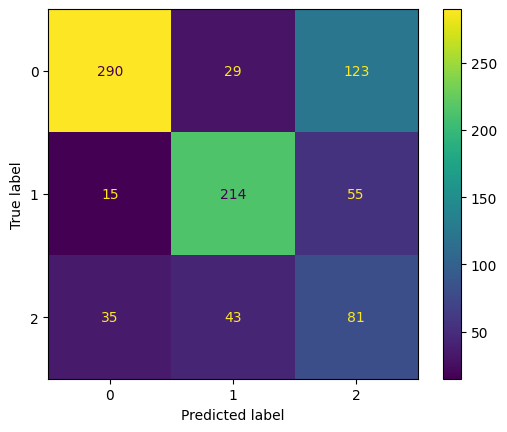

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.85      0.66      0.74       442
           1       0.75      0.75      0.75       284
           2       0.31      0.51      0.39       159

    accuracy                           0.66       885
   macro avg       0.64      0.64      0.63       885
weighted avg       0.72      0.66      0.68       885



In [ ]:
# Undersampling method - RBF kernel - C =1, Gamma = 10
rbfunder_svm = SVC(kernel = 'rbf', C= 1.0, decision_function_shape='ovo',
                   gamma =10 )

rbfunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= rbfunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with RBF kernel, C = 1.0, Gamma = 10.0  {0:0.4f}'. format(accuracy_score(y_test, y_pred_under)))

Undersampling data - Model Accuracy score with RBF kernel, C = 1.0, Gamma = 10.0  0.3198


In [ ]:
##×Checking over fitting:
# print the scores on training and testing set

print('Training set score: {:.4f}'.format(rbfunder_svm.score(X_train_under, y_resampled_under)))

print('Test set score: {:.4f}'.format(rbfunder_svm.score(X_test , y_test)))

Training set score: 1.0000
Test set score: 0.3198


**RBF kernel, C = 1, Gamma = 10 - Undersampling - confusion matrix**

[[  0 442   0]
 [  0 283   1]
 [  0 159   0]]


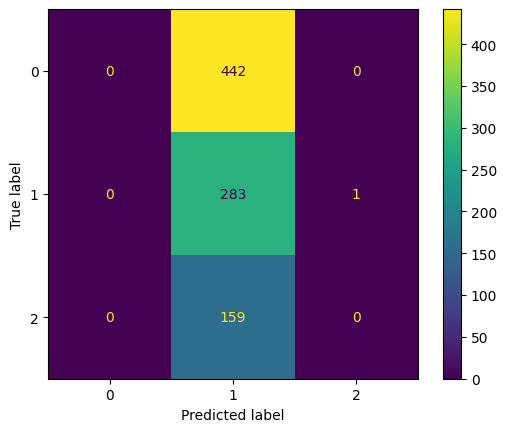

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       442
           1       0.32      1.00      0.48       284
           2       0.00      0.00      0.00       159

    accuracy                           0.32       885
   macro avg       0.11      0.33      0.16       885
weighted avg       0.10      0.32      0.16       885



**SMOTE method - RBF kernel**

In [ ]:
# SMOTE method - RBF kernel - C =1, Gamma = auto
rbfsmote_svm = SVC(kernel = 'rbf', C= 1, decision_function_shape='ovo',
                   gamma = 'auto' )

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = auto  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = auto  0.6734


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  0.8708
Test set score 0.6734


[[315  34  93]
 [ 32 198  54]
 [ 42  34  83]]


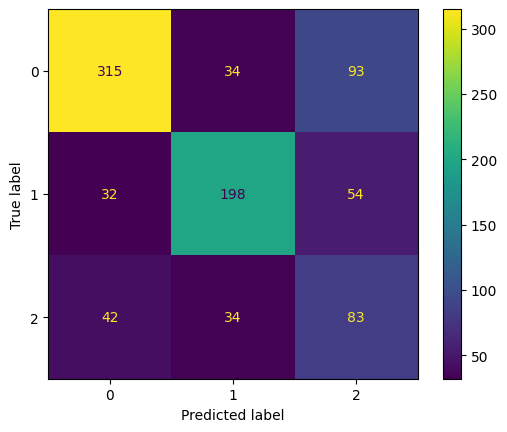

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.81      0.71      0.76       442
           1       0.74      0.70      0.72       284
           2       0.36      0.52      0.43       159

    accuracy                           0.67       885
   macro avg       0.64      0.64      0.63       885
weighted avg       0.71      0.67      0.69       885



In [ ]:
# SMOTE method - RBF kernel - C =100.0, Gamma = auto
rbfsmote_svm = SVC(kernel = 'rbf', C= 100.0, decision_function_shape='ovo',
                   gamma = 'auto' )

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 100.0, Gamma = auto  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy score with RBF kernel, C = 100.0, Gamma = auto  0.6520


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  1.0000
Test set score 0.6520


[[313  47  82]
 [ 37 199  48]
 [ 44  50  65]]


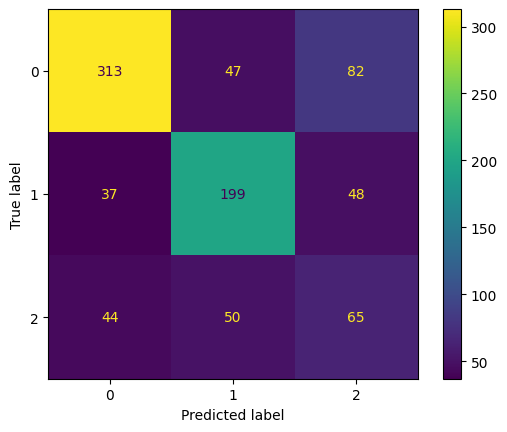

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.79      0.71      0.75       442
           1       0.67      0.70      0.69       284
           2       0.33      0.41      0.37       159

    accuracy                           0.65       885
   macro avg       0.60      0.61      0.60       885
weighted avg       0.67      0.65      0.66       885



In [ ]:
# SMOTE method - RBF kernel - C =1, Gamma = 0.001
rbfsmote_svm = SVC(kernel = 'rbf', C= 1, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = 0.001  0.6734


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  0.7883
Test set score 0.6734


[[304  31 107]
 [ 21 202  61]
 [ 40  29  90]]


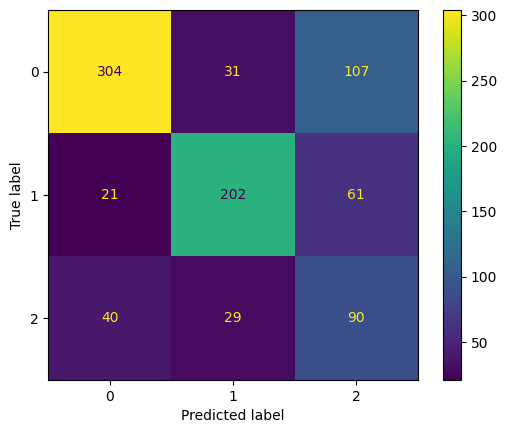

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.83      0.69      0.75       442
           1       0.77      0.71      0.74       284
           2       0.35      0.57      0.43       159

    accuracy                           0.67       885
   macro avg       0.65      0.66      0.64       885
weighted avg       0.73      0.67      0.69       885



In [ ]:
# SMOTE method - RBF kernel - C =10.0, Gamma = 0.001
rbfsmote_svm = SVC(kernel = 'rbf', C= 10.0, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 10.0, Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy score with RBF kernel, C = 10.0, Gamma = 0.001  0.6746


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  0.8659
Test set score 0.6746


[[302  34 106]
 [ 19 208  57]
 [ 34  38  87]]


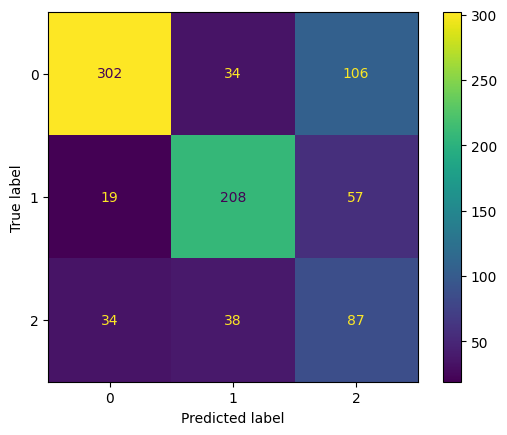

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.85      0.68      0.76       442
           1       0.74      0.73      0.74       284
           2       0.35      0.55      0.43       159

    accuracy                           0.67       885
   macro avg       0.65      0.65      0.64       885
weighted avg       0.73      0.67      0.69       885



In [ ]:
# SMOTE method - RBF kernel - C =100, Gamma = 0.001
rbfsmote_svm = SVC(kernel = 'rbf', C= 100.0, decision_function_shape='ovo',
                   gamma = 0.001 )

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 100, Gamma = 0.001  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy score with RBF kernel, C = 100, Gamma = 0.001  0.6723


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  0.9583
Test set score 0.6723


[[312  34  96]
 [ 25 209  50]
 [ 37  48  74]]


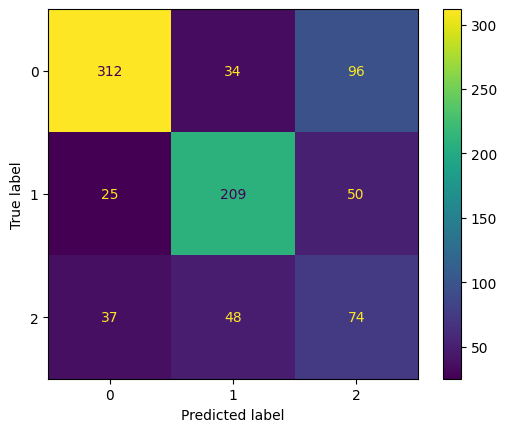

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.83      0.71      0.76       442
           1       0.72      0.74      0.73       284
           2       0.34      0.47      0.39       159

    accuracy                           0.67       885
   macro avg       0.63      0.64      0.63       885
weighted avg       0.71      0.67      0.69       885



In [ ]:
# SMOTE method - RBF kernel - C =1, Gamma = 10
rbfsmote_svm = SVC(kernel = 'rbf', C= 1, decision_function_shape='ovo',
                   gamma = 10)

rbfsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote= rbfsmote_svm.predict(X_test)

print('SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = 10  {0:0.4f}'. format(accuracy_score(y_test, y_pred_smote)))


SMOTE method - Model Accuracy score with RBF kernel, C = 1, Gamma = 10  0.4994


In [ ]:
#Checking Overfittting and underfittting
print("Training set score  {:.4f}".format (rbfsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score {:.4f}".format(rbfsmote_svm.score(X_test, y_test)))

Training set score  1.0000
Test set score 0.4994


[[442   0   0]
 [284   0   0]
 [159   0   0]]


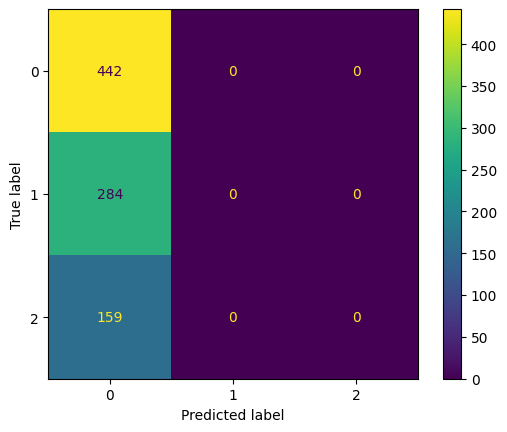

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote,zero_division=0))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67       442
           1       0.00      0.00      0.00       284
           2       0.00      0.00      0.00       159

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885



**RBF kernel Accuracy - Comparision bwtween imbalance data - SMOTE - Undersampling**

In [ ]:
C_values = [1, 10, 100]
gamma_values = [ 0.001, 0.1 , 1 , 'auto' , 'scale']

#imbalance data
imaccuracy_rbf =np.zeros((len(C_values), len(gamma_values)))

In [ ]:
#Undersampling mehtod
underaccuracy_rbf =np.zeros((len(C_values), len(gamma_values)))

In [ ]:
#smote mehtod
smoteaccuracy_rbf =np.zeros((len(C_values), len(gamma_values)))

In [ ]:
# Results from RBF kernel with imbalance data:
for i, C in enumerate(C_values):
    for j, gamma in enumerate(gamma_values):
        model_im = SVC(kernel='rbf', C=C, gamma=gamma)
        model_im.fit(X_train, y_train)           # training data
        y_pred_imbalance2 = model_im.predict(X_test)        # testing data
        acc = accuracy_score(y_test, y_pred_imbalance2)  # compute accuracy
        imaccuracy_rbf[i, j] = acc                  # store in matrix

In [ ]:

# Results from RBF kernel with undersampling:
for i, C in enumerate(C_values):
    for j, gamma in enumerate(gamma_values):
        model_under = SVC(kernel='rbf', C=C, gamma=gamma)
        model_under.fit(X_train_under, y_resampled_under)           # training data
        y_pred_under2= model_under.predict(X_test)        # testing data
        acc = accuracy_score(y_test, y_pred_under2)  # compute accuracy
        underaccuracy_rbf[i, j] = acc                  # store in matrix

In [ ]:
# Results from RBF kernel with smote:
for i, C in enumerate(C_values):
    for j, gamma in enumerate(gamma_values):
        model_smote = SVC(kernel='rbf', C=C, gamma=gamma)
        model_smote.fit(X_train_smote, y_resampled_smote)           # training data
        y_pred_smote2 = model_smote.predict(X_test)        # testing data
        acc = accuracy_score(y_test, y_pred_smote2)  # compute accuracy
        smoteaccuracy_rbf[i, j] = acc                  # store in matrix

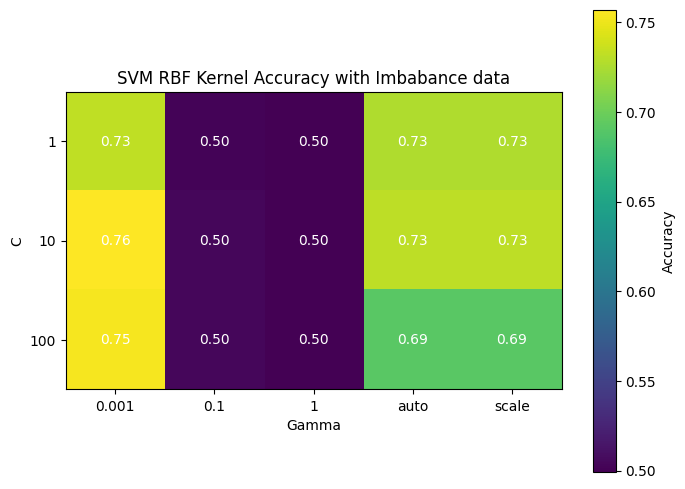

In [ ]:
plt.figure(figsize=(8,6))
plt.imshow(imaccuracy_rbf, interpolation='nearest', cmap='viridis')
plt.title("SVM RBF Kernel Accuracy with Imbabance data")
plt.xlabel('Gamma')
plt.ylabel('C')
plt.colorbar(label='Accuracy')

# Add ticks
plt.xticks(np.arange(len(gamma_values)), gamma_values)
plt.yticks(np.arange(len(C_values)), C_values)

# Annotate accuracy numbers
for i in range(len(C_values)):
    for j in range(len(gamma_values)):
        plt.text(j, i, f"{imaccuracy_rbf[i,j]:.2f}", ha='center', va='center', color='white')

plt.show()

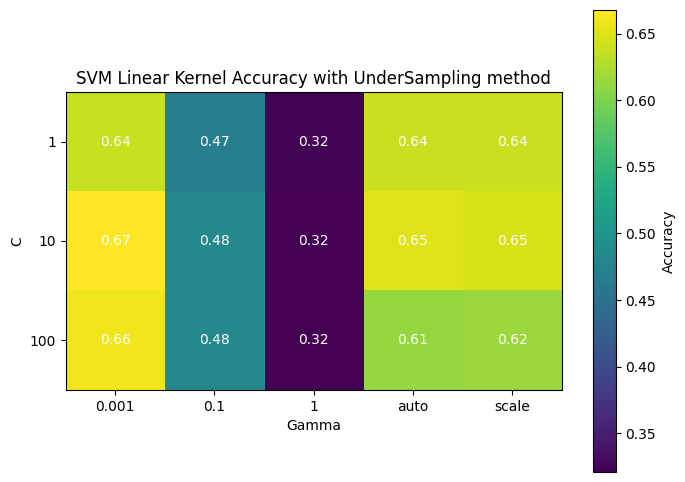

In [ ]:
plt.figure(figsize=(8,6))
plt.imshow(underaccuracy_rbf, interpolation='nearest', cmap='viridis')
plt.title("SVM Rbf Kernel Accuracy with UnderSampling method")
plt.xlabel('Gamma')
plt.ylabel('C')
plt.colorbar(label='Accuracy')

# Add ticks
plt.xticks(np.arange(len(gamma_values)), gamma_values)
plt.yticks(np.arange(len(C_values)), C_values)

# Annotate accuracy numbers
for i in range(len(C_values)):
    for j in range(len(gamma_values)):
        plt.text(j, i, f"{underaccuracy_rbf[i,j]:.2f}", ha='center', va='center', color='white')

plt.show()

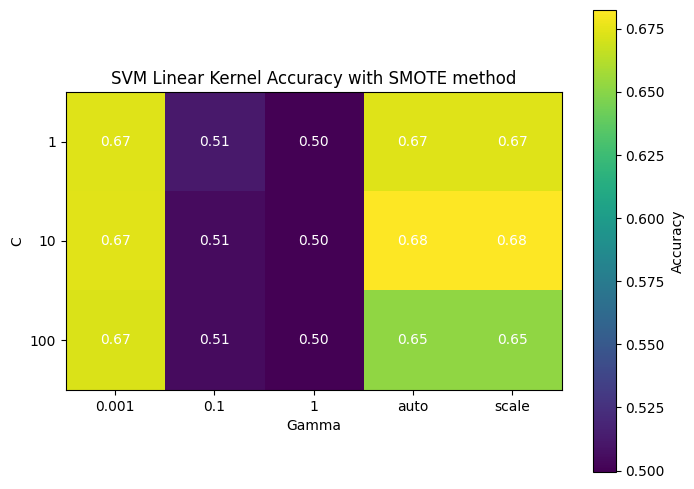

In [ ]:
plt.figure(figsize=(8,6))
plt.imshow(smoteaccuracy_rbf, interpolation='nearest', cmap='viridis')
plt.title("SVM Rbf Kernel Accuracy with SMOTE method")
plt.xlabel('Gamma')
plt.ylabel('C')
plt.colorbar(label='Accuracy')

# Add ticks
plt.xticks(np.arange(len(gamma_values)), gamma_values)
plt.yticks(np.arange(len(C_values)), C_values)

# Annotate accuracy numbers
for i in range(len(C_values)):
    for j in range(len(gamma_values)):
        plt.text(j, i, f"{smoteaccuracy_rbf[i,j]:.2f}", ha='center', va='center', color='white')

plt.show()